In [10]:
# imports
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from plyfile import PlyData
from scipy.ndimage import minimum_filter
from scipy.spatial import cKDTree
from scipy.signal import savgol_filter
import os

from data_loader import * 


In [2]:
# edit root paths
ROOT_PATH = project_root = Path.cwd().parent
KITTI_360_ROOT = Path(ROOT_PATH / "KITTI-360")

SEQ = "2013_05_28_drive_0000_sync"
CAM_ID = 0 # 0 = left pov, 1 right pov
SPLIT = "train"
FRAME = 385
ROAD_ID = 7
SIDEWALK_ID = 8

In [3]:
proj_matrix, W, H = load_perspective_calibration(KITTI_360_ROOT, CAM_ID)
poses = load_cam0_to_world(KITTI_360_ROOT, SEQ)
print(f"image size: {W, H}")
print(proj_matrix)


image size: (1408, 376)
[['552.554261' '0.000000' '682.049453' '0.000000']
 ['0.000000' '552.554261' '238.769549' '0.000000']
 ['0.000000' '0.000000' '1.000000' '0.000000']]


In [4]:
chunks = list_static_chunks(KITTI_360_ROOT, SPLIT, SEQ)
print(chunks[:5])
print(len(chunks), "static chunks")
hit = get_chunks_for_frame(chunks, FRAME)
print("chunks covering frame", FRAME, ":", [c[2].name for c in hit])

cloud = load_cloud_for_frame(chunks, FRAME)

[(2, 385, PosixPath('/Users/mariasilva/Documents/CurbDetect/KITTI-360/data_3d_semantics/train/2013_05_28_drive_0000_sync/static/0000000002_0000000385.ply')), (372, 610, PosixPath('/Users/mariasilva/Documents/CurbDetect/KITTI-360/data_3d_semantics/train/2013_05_28_drive_0000_sync/static/0000000372_0000000610.ply')), (599, 846, PosixPath('/Users/mariasilva/Documents/CurbDetect/KITTI-360/data_3d_semantics/train/2013_05_28_drive_0000_sync/static/0000000599_0000000846.ply')), (834, 1286, PosixPath('/Users/mariasilva/Documents/CurbDetect/KITTI-360/data_3d_semantics/train/2013_05_28_drive_0000_sync/static/0000000834_0000001286.ply')), (1270, 1549, PosixPath('/Users/mariasilva/Documents/CurbDetect/KITTI-360/data_3d_semantics/train/2013_05_28_drive_0000_sync/static/0000001270_0000001549.ply'))]
44 static chunks
chunks covering frame 385 : ['0000000002_0000000385.ply', '0000000372_0000000610.ply']
0000000002_0000000385.ply: 3,201,318 points, fields: ('x', 'y', 'z', 'red', 'green', 'blue', 'seman

In [5]:
def visible_mask(u, v, z, W, H, k=5, tol=0.7): 
    depth = np.full((H, W), np.inf)
    u_i, v_i = u.astype(int), v.astype(int)
    order = np.argsort(-z) # far to near pts, nearest written last
    depth[v_i[order], u_i[order]] = z[order]
    local_min = minimum_filter(depth, size=k)
    return z <= local_min[v_i, u_i] + tol
cam_2_world = poses[FRAME]
u, v, z, idx = project(cloud["xyz"], cam_2_world, proj_matrix, W, H)
vis = visible_mask(u, v, z, W, H)
u, v, z, idx = u[vis], v[vis], z[vis], idx[vis]
print(f"{len(idx):,} visible points projected")


246,094 visible points projected


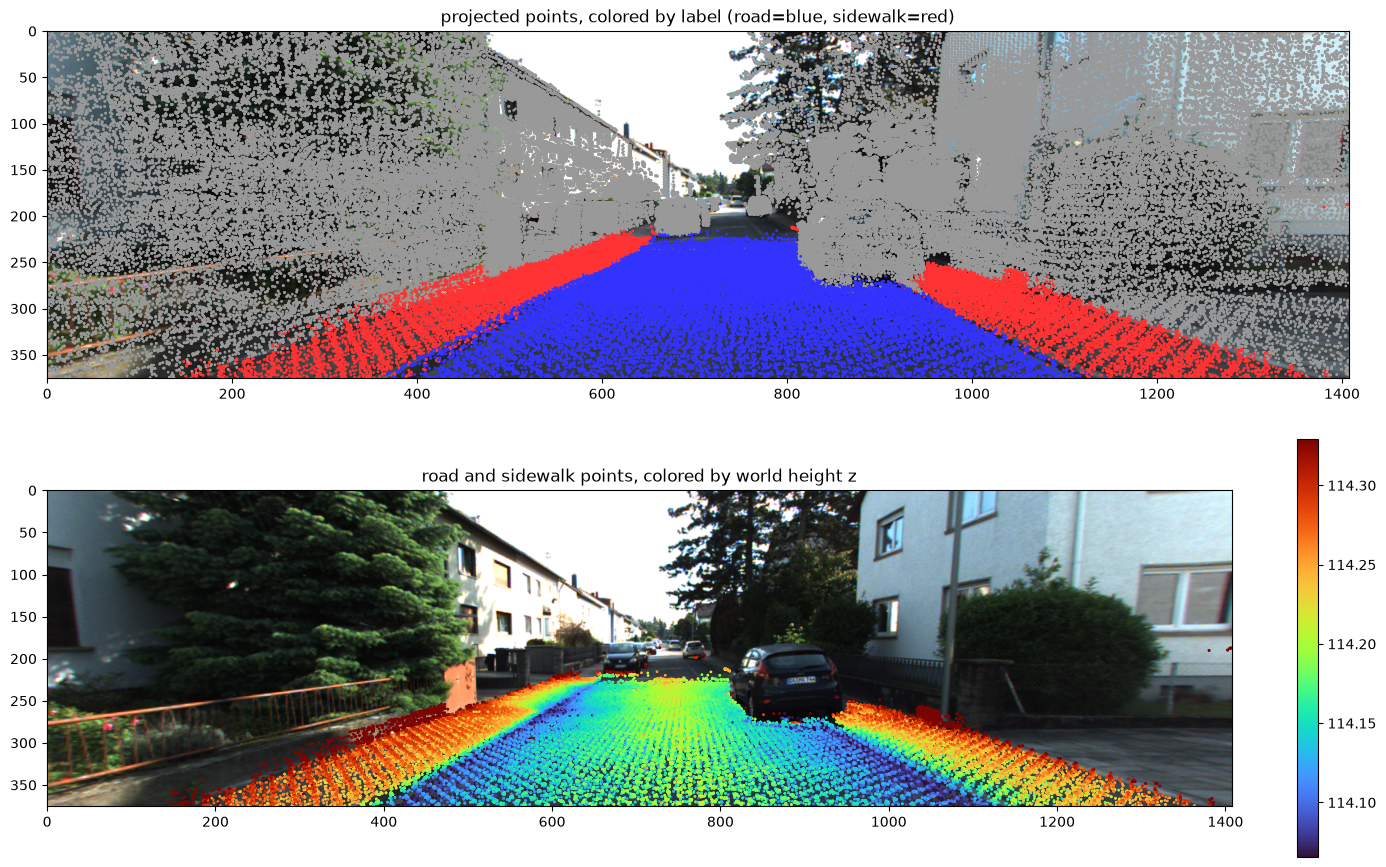

In [ ]:
img = np.array(Image.open(get_img_path(KITTI_360_ROOT, SEQ, CAM_ID, FRAME)))

def label_colours(sem):
    colour_mask = np.full((len(sem), 3), 0.6) # everything_grey
    colour_mask[sem == ROAD_ID] = (0.2, 0.2, 1.0) # road = blue
    colour_mask[sem == SIDEWALK_ID] = (1.0, 0.2, 0.2) # sidewalk = red
    return colour_mask

fig, axes = plt.subplots(2, 1, figsize=(14, 9))
for ax in axes:
    ax.imshow(img)

ground = np.isin(cloud["semantic"][idx], [ROAD_ID, SIDEWALK_ID])
axes[0].scatter(u, v, s=1, c=label_colours(cloud["semantic"][idx]))
axes[0].set_title("projected points, colored by label (road=blue, sidewalk=red)")

depth = cloud["xyz"][idx, 2]
lo, hi = np.percentile(depth[ground], [2, 98]) if ground.any() else (depth.min(), depth.max())
sc = axes[1].scatter(u[ground], v[ground], s=1, c=depth[ground], cmap="turbo", vmin=lo, vmax=hi)
axes[1].set_title("road and sidewalk points, colored by world height z")
plt.colorbar(sc, ax=axes[1], fraction=0.04)
plt.tight_layout()
plt.show()

In [11]:
def boundary_candidates(cloud, road_id, sidewalk_id, n=30, radius=0.3, min_spacing=15.0, max_road_pts=300_000, seed=0):
    random_gen = np.random.default_rng(seed)
    xyz = cloud["xyz"][:, :2]
    semantic = cloud["semantic"]
    road = xyz[semantic == road_id] # n x m array
    sidewalk = xyz[semantic == sidewalk_id] # n x m array

    if len(road) == 0 or len(sidewalk) == 0:
        return np.empty((0, 2))
    if len(road) > max_road_pts:
        road = road[random_gen.choice(len(road), max_road_pts, replace=False)] # resample

    distance, _ = cKDTree(sidewalk).query(road, distance_upper_bound=radius) # spatial search mapping closest points of sidewalk to query - within a radius
    edge = road[np.isfinite(distance)]
    random_gen.shuffle(edge) # to not prioritize ordered points

    picked = []
    for p in edge: 
        if all(np.hypot(*(p - q)) > min_spacing for q in picked): # euclidian distance > min spacing threshold between pts
            picked.append(p)
            if len(picked) == n: 
                break
    return np.array(picked)


def analyze_boundary(cloud, center_xy, road_id, sidewalk_id, half=4.0, strip=2.0,
                     edge_radius=0.3, bin_w=0.05, margin=0.15, min_pts=30):
    xyz = cloud["xyz"]
    semantic = cloud["semantic"]
    center_xy = np.asarray(center_xy, float)

    # window around the centered point
    window = (np.abs(xyz[:, 0] - center_xy[0]) < half) & (np.abs(xyz[:, 1] - center_xy[1]) < half)
    window &= np.isin(semantic, [road_id, sidewalk_id])
    idx = np.where(window)[0]

    if len(idx) < min_pts:
        return None
    
    point_coords = xyz[idx, :2]
    z = xyz[idx, 2]

    road = point_coords[semantic[idx] == road_id]
    side = point_coords[semantic[idx] == sidewalk_id]

    if len(road) < 10 or len(side) < 10:
        return None

    # label-edge points: road points that touch sidewalk points
    dist, _ = cKDTree(side).query(road, distance_upper_bound=edge_radius)
    edge = road[np.isfinite(dist)]
    if len(edge) < 10:
        return None

    # local frame: t along the boundary (PCA), n across it, pointing road -> sidewalk
    o = edge.mean(0)
    w, v = np.linalg.eigh(np.cov((edge - o).T))
    t = v[:, np.argmax(w)]
    n = np.array([-t[1], t[0]])
    if (side.mean(0) - road.mean(0)) @ n < 0:
        n = -n

    # restrict to a strip around the center
    along, across = (point_coords - o) @ t, (point_coords - o) @ n
    keep = np.abs(along) < strip / 2

    if keep.sum() < min_pts:
        return None
    
    boundary_pt_pos, height, label = across[keep], z[keep], semantic[idx][keep]
    road_pos = boundary_pt_pos[label == road_id]
    sidewalk_pos = boundary_pt_pos[label == sidewalk_id]

    if len(road_pos) < 5 or len(sidewalk_pos) < 5:
        return None

    # get rid of extremes
    semantic_label = 0.5 * (np.percentile(road_pos, 95) + np.percentile(sidewalk_pos, 5))

    # identify edges
    edges = np.arange(boundary_pt_pos.min(), boundary_pt_pos.max() + bin_w, bin_w)
    b = np.digitize(boundary_pt_pos, edges)

    centers, meds, cnt = [], [], []
    for k in np.unique(b):
        m = b == k
        if m.sum() >= 3:
            centers.append(boundary_pt_pos[m].mean()); meds.append(np.median(height[m])); cnt.append(m.sum())
    centers, meds, cnt = map(np.array, (centers, meds, cnt))

    if len(centers) < 6:
        return None

    # smooth the binned median heights
    meds_smooth = savgol_filter(meds, window_length=5, polyorder=2)

    if len(centers) < 6:
        return None

    # fit the step between the two
    best = np.inf # want this to be a min 
    step = np.nan

    for i in range(2, len(centers) - 2):
        left = slice(0, i) # split at the boundary i
        right = slice(i, None)
        left_avg = np.average(meds_smooth[left], weights=cnt[left])
        right_avg = np.average(meds_smooth[right], weights=cnt[right])
        cost = (cnt[left] * (meds_smooth[left] - left_avg) ** 2).sum() + (cnt[right] * (meds_smooth[right] - right_avg) ** 2).sum() # weighted squared error for both left anf right sides around the boundary
        
        if cost < best:
            best = cost
            step = 0.5 * (centers[i - 1] + centers[i]) # step is the midpoint

    left, right = boundary_pt_pos < step - margin, boundary_pt_pos > step + margin

    if left.sum() >= 5 and right.sum() >= 5:
        step_cm = (np.median(height[right]) - np.median(height[left])) * 100
    else: 
        step_cm = np.nan

    return dict(center=center_xy, o=o, t=t, n=n, s=boundary_pt_pos, z=height, lab=label, bins=(centers, meds_smooth),
                s_label=semantic_label, s_step=step, step_cm=step_cm,
                offset_cm=(step - semantic_label) * 100, window=(point_coords, semantic[idx], z),
                road_id=road_id, sidewalk_id=sidewalk_id)
